# Demographic & Economic Analysis of Polish Regions
## 03 - Statistical Analysis

This notebook examines statistical relationships between demographic and
socioeconomic indicators across Polish voivodeships.

The analysis focuses on three hypotheses:

1. Higher unemployment is associated with a less favourable migration balance.
2. Higher salary levels are associated with a more favourable migration balance.
3. Stronger population ageing is associated with population decline.

Both Pearson and Spearman correlation coefficients are considered where
appropriate. The results are interpreted as associations and do not imply
causal relationships.

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import pearsonr, spearmanr

In [22]:
DATA_PATH = Path("../data/processed/polish_regions_analysis_ready.csv")

In [23]:
df = pd.read_csv(
    DATA_PATH,
    dtype={"unit_id": str}
)

print(df.shape)
display(df.head())

(256, 12)


,unit_id,voivodeship,year,population,migration_balance,migration_balance_per_1000,natural_increase,natural_increase_per_1000,unemployment_rate,monthly_gross_salary_per_employee,population_65_plus,population_65_plus_share
0,011200000000,MAŁOPOLSKIE,2010,3336699,4408.0,1.32,7416,2.23,NaN,2997.0,453027,13.577101
1,011200000000,MAŁOPOLSKIE,2011,3346796,4300.0,1.29,5797,1.74,10.5,3148.0,462310,13.813510
2,011200000000,MAŁOPOLSKIE,2012,3354077,3577.0,1.07,4529,1.35,11.4,3352.0,473819,14.126658
3,011200000000,MAŁOPOLSKIE,2013,3360581,2824.0,0.84,4030,1.20,11.5,3431.0,487081,14.493952
4,011200000000,MAŁOPOLSKIE,2014,3368336,2947.0,0.88,4808,1.43,9.7,3573.0,501278,14.882066


In [24]:
assert df.shape == (256, 12)
assert df["voivodeship"].nunique() == 16
assert df.duplicated(["unit_id", "year"]).sum() == 0

assert df.loc[
    df["year"] == 2015,
    ["migration_balance", "migration_balance_per_1000"]
].isna().all().all()

print("Dataset validation passed.")

Dataset validation passed.


## 1. Unemployment and migration

### Hypothesis 1

Higher registered unemployment is associated with a less favourable migration
balance.

The first analysis uses all available voivodeship-year observations. Because
the dataset contains repeated observations for the same regions over time,
the resulting pooled correlation is treated as a descriptive measure rather
than as evidence of independent observations or causality.

In [25]:
h1_data = (
    df[
        [
            "voivodeship",
            "year",
            "unemployment_rate",
            "migration_balance_per_1000"
        ]
    ]
    .dropna()
)

print("Number of observations:", len(h1_data))

Number of observations: 224


In [26]:
pearson_r, pearson_p = pearsonr(
    h1_data["unemployment_rate"],
    h1_data["migration_balance_per_1000"]
)

spearman_rho, spearman_p = spearmanr(
    h1_data["unemployment_rate"],
    h1_data["migration_balance_per_1000"]
)

print(f"Pearson r:    {pearson_r:.3f}")
print(f"Pearson p:    {pearson_p:.4f}")

print()

print(f"Spearman rho: {spearman_rho:.3f}")
print(f"Spearman p:   {spearman_p:.4f}")

Pearson r:    -0.439
Pearson p:    0.0000

Spearman rho: -0.493
Spearman p:   0.0000


In [27]:
h1_regional = (
    h1_data
    .groupby("voivodeship")
    .agg(
        avg_unemployment_rate=(
            "unemployment_rate",
            "mean"
        ),
        avg_migration_per_1000=(
            "migration_balance_per_1000",
            "mean"
        )
    )
    .reset_index()
)

display(h1_regional)

,voivodeship,avg_unemployment_rate,avg_migration_per_1000
0,DOLNOŚLĄSKIE,7.242857,0.971429
1,KUJAWSKO-POMORSKIE,11.000000,-0.980000
2,LUBELSKIE,9.785714,-2.368571
3,LUBUSKIE,8.257143,-0.887857
4,MAZOWIECKIE,6.400000,2.530000
5,MAŁOPOLSKIE,6.535714,1.340000
6,OPOLSKIE,8.535714,-1.641429
7,PODKARPACKIE,11.071429,-1.083571
8,PODLASKIE,9.585714,-1.412143
9,POMORSKIE,7.307143,1.683571


In [28]:
h1_regional_pearson_r, h1_regional_pearson_p = pearsonr(
    h1_regional["avg_unemployment_rate"],
    h1_regional["avg_migration_per_1000"]
)

h1_regional_spearman_rho, h1_regional_spearman_p = spearmanr(
    h1_regional["avg_unemployment_rate"],
    h1_regional["avg_migration_per_1000"]
)

print(f"Regional Pearson r:    {h1_regional_pearson_r:.3f}")
print(f"Regional Pearson p:    {h1_regional_pearson_p:.4f}")

print()

print(f"Regional Spearman rho: {h1_regional_spearman_rho:.3f}")
print(f"Regional Spearman p:   {h1_regional_spearman_p:.4f}")

Regional Pearson r:    -0.671
Regional Pearson p:    0.0045

Regional Spearman rho: -0.668
Regional Spearman p:   0.0047


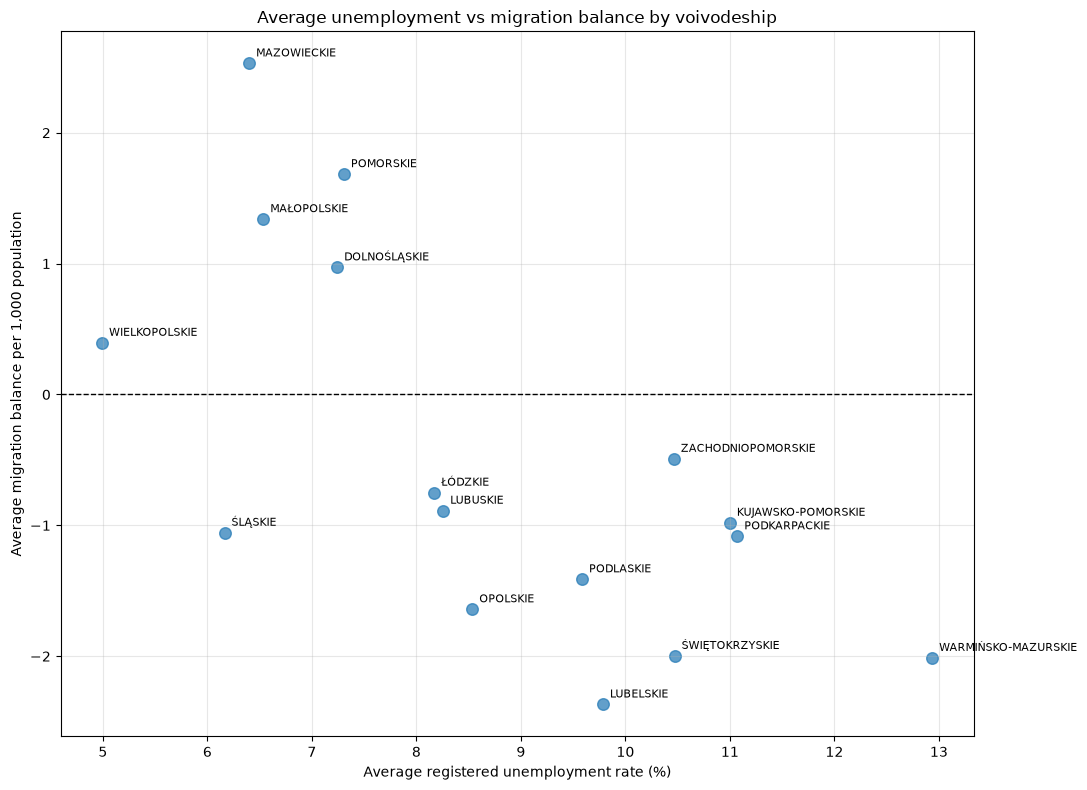

In [29]:
plt.figure(figsize=(11, 8))

plt.scatter(
    h1_regional["avg_unemployment_rate"],
    h1_regional["avg_migration_per_1000"],
    s=70,
    alpha=0.7
)

for _, row in h1_regional.iterrows():
    plt.annotate(
        row["voivodeship"],
        (
            row["avg_unemployment_rate"],
            row["avg_migration_per_1000"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Average registered unemployment rate (%)")
plt.ylabel("Average migration balance per 1,000 population")
plt.title("Average unemployment vs migration balance by voivodeship")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

Both pooled and regional analyses indicate a negative association between
registered unemployment and migration balance.

Using 224 voivodeship-year observations, the Pearson correlation was -0.439
and the Spearman correlation was -0.493, indicating a moderate negative
association.

The relationship was stronger when long-term regional averages were compared
across the 16 voivodeships. The regional Pearson correlation was -0.671
(p = 0.0045), while the Spearman correlation was -0.668 (p = 0.0047).

These results are consistent with Hypothesis 1: voivodeships with higher
unemployment tended to have less favourable migration balances.

The results should not be interpreted as evidence that unemployment causes
migration. Other economic, demographic and regional factors may influence
both indicators. In addition, pooled observations contain repeated
measurements of the same voivodeships over time.

## 2. Salary and migration

### Hypothesis 2

Higher monthly gross salary per employee is associated with a more favourable
migration balance.

The analysis first examines the pooled relationship using all available
voivodeship-year observations and then compares long-term regional averages.

Because salary values are nominal and increased substantially over time,
pooled correlations may partly reflect common time trends rather than purely
regional differences.

In [30]:
h2_data = (
    df[
        [
            "voivodeship",
            "year",
            "monthly_gross_salary_per_employee",
            "migration_balance_per_1000"
        ]
    ]
    .dropna()
)

print("Number of observations:", len(h2_data))

Number of observations: 224


In [31]:
h2_pearson_r, h2_pearson_p = pearsonr(
    h2_data["monthly_gross_salary_per_employee"],
    h2_data["migration_balance_per_1000"]
)

h2_spearman_rho, h2_spearman_p = spearmanr(
    h2_data["monthly_gross_salary_per_employee"],
    h2_data["migration_balance_per_1000"]
)

print(f"Pearson r:    {h2_pearson_r:.3f}")
print(f"Pearson p:    {h2_pearson_p:.4f}")

print()

print(f"Spearman rho: {h2_spearman_rho:.3f}")
print(f"Spearman p:   {h2_spearman_p:.4f}")

Pearson r:    0.390
Pearson p:    0.0000

Spearman rho: 0.351
Spearman p:   0.0000


In [32]:
h2_regional = (
    h2_data
    .groupby("voivodeship")
    .agg(
        avg_salary=(
            "monthly_gross_salary_per_employee",
            "mean"
        ),
        avg_migration_per_1000=(
            "migration_balance_per_1000",
            "mean"
        )
    )
    .reset_index()
)

display(h2_regional)

,voivodeship,avg_salary,avg_migration_per_1000
0,DOLNOŚLĄSKIE,5239.071429,0.915714
1,KUJAWSKO-POMORSKIE,4236.571429,-0.994286
2,LUBELSKIE,4149.285714,-2.360714
3,LUBUSKIE,4244.071429,-0.872857
4,MAZOWIECKIE,6237.571429,2.541429
5,MAŁOPOLSKIE,4980.428571,1.305714
6,OPOLSKIE,4573.500000,-1.683571
7,PODKARPACKIE,4049.357143,-1.061429
8,PODLASKIE,4119.714286,-1.417143
9,POMORSKIE,5071.142857,1.601429


In [33]:
h2_regional_pearson_r, h2_regional_pearson_p = pearsonr(
    h2_regional["avg_salary"],
    h2_regional["avg_migration_per_1000"]
)

h2_regional_spearman_rho, h2_regional_spearman_p = spearmanr(
    h2_regional["avg_salary"],
    h2_regional["avg_migration_per_1000"]
)

print(f"Regional Pearson r:    {h2_regional_pearson_r:.3f}")
print(f"Regional Pearson p:    {h2_regional_pearson_p:.4f}")

print()

print(f"Regional Spearman rho: {h2_regional_spearman_rho:.3f}")
print(f"Regional Spearman p:   {h2_regional_spearman_p:.4f}")

Regional Pearson r:    0.829
Regional Pearson p:    0.0001

Regional Spearman rho: 0.715
Regional Spearman p:   0.0019


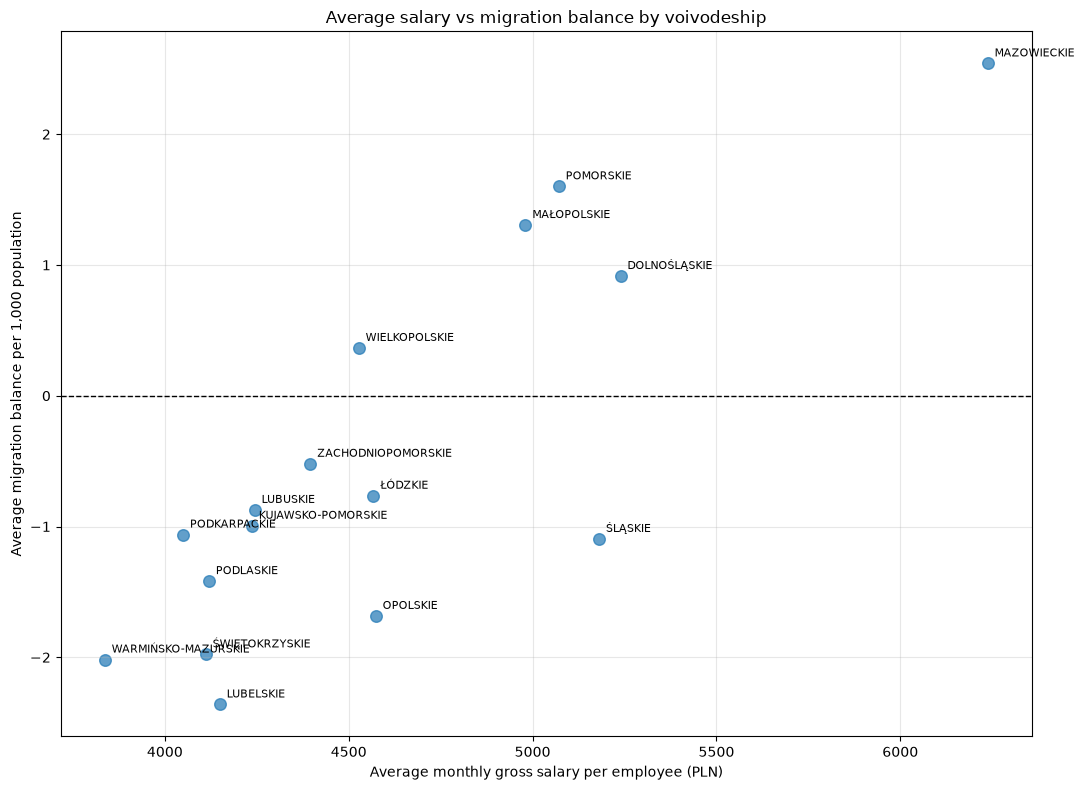

In [34]:
plt.figure(figsize=(11, 8))

plt.scatter(
    h2_regional["avg_salary"],
    h2_regional["avg_migration_per_1000"],
    s=70,
    alpha=0.7
)

for _, row in h2_regional.iterrows():
    plt.annotate(
        row["voivodeship"],
        (
            row["avg_salary"],
            row["avg_migration_per_1000"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Average monthly gross salary per employee (PLN)")
plt.ylabel("Average migration balance per 1,000 population")
plt.title("Average salary vs migration balance by voivodeship")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

Both pooled and regional analyses indicate a positive association between
monthly gross salary per employee and migration balance.

Using 224 voivodeship-year observations, the Pearson correlation was 0.390
and the Spearman correlation was 0.351, indicating a moderate positive
association.

The relationship was considerably stronger when long-term regional averages
were compared across the 16 voivodeships. The regional Pearson correlation
was 0.829 (p = 0.0001), while the Spearman correlation was 0.715
(p = 0.0019).

These results are consistent with Hypothesis 2: voivodeships with higher
salary levels tended to have more favourable migration balances.

The pooled results should be interpreted with particular caution because
nominal salaries increased substantially over time across all regions.
The regional comparison reduces the influence of year-to-year fluctuations,
but the observed association still does not establish a causal relationship.
Other regional characteristics may influence both salary levels and migration.

## 3. Population ageing and population change

### Hypothesis 3

A stronger increase in the share of population aged 65 and over is associated
with less favourable population change.

Unlike the previous analyses, this hypothesis focuses on long-term changes
between 2010 and 2025. Therefore, each voivodeship is represented by one
observation.

In [35]:
population_2010 = (
    df[df["year"] == 2010]
    [["voivodeship", "population"]]
    .rename(columns={"population": "population_2010"})
)

population_2025 = (
    df[df["year"] == 2025]
    [["voivodeship", "population"]]
    .rename(columns={"population": "population_2025"})
)

ageing_2010 = (
    df[df["year"] == 2010]
    [["voivodeship", "population_65_plus_share"]]
    .rename(columns={
        "population_65_plus_share": "share_65_plus_2010"
    })
)

ageing_2025 = (
    df[df["year"] == 2025]
    [["voivodeship", "population_65_plus_share"]]
    .rename(columns={
        "population_65_plus_share": "share_65_plus_2025"
    })
)

In [36]:
h3_data = (
    population_2010
    .merge(
        population_2025,
        on="voivodeship",
        validate="one_to_one"
    )
    .merge(
        ageing_2010,
        on="voivodeship",
        validate="one_to_one"
    )
    .merge(
        ageing_2025,
        on="voivodeship",
        validate="one_to_one"
    )
)

In [37]:
h3_data["population_change_pct"] = (
    (
        h3_data["population_2025"]
        - h3_data["population_2010"]
    )
    / h3_data["population_2010"]
    * 100
)

h3_data["ageing_change_pp"] = (
    h3_data["share_65_plus_2025"]
    - h3_data["share_65_plus_2010"]
)

display(
    h3_data[
        [
            "voivodeship",
            "ageing_change_pp",
            "population_change_pct"
        ]
    ].sort_values(
        "population_change_pct",
        ascending=False
    )
)

,voivodeship,ageing_change_pp,population_change_pct
15,MAZOWIECKIE,5.416663,4.533543
8,POMORSKIE,7.274574,3.643824
0,MAŁOPOLSKIE,5.628536,2.776487
3,WIELKOPOLSKIE,7.785079,0.712469
5,DOLNOŚLĄSKIE,8.648189,-2.055675
13,PODKARPACKIE,7.125043,-3.486363
2,LUBUSKIE,9.877316,-5.826146
7,KUJAWSKO-POMORSKIE,8.829356,-6.042757
14,PODLASKIE,6.624252,-6.379087
4,ZACHODNIOPOMORSKIE,10.368559,-6.443021


In [38]:
h3_pearson_r, h3_pearson_p = pearsonr(
    h3_data["ageing_change_pp"],
    h3_data["population_change_pct"]
)

h3_spearman_rho, h3_spearman_p = spearmanr(
    h3_data["ageing_change_pp"],
    h3_data["population_change_pct"]
)

print(f"Pearson r:    {h3_pearson_r:.3f}")
print(f"Pearson p:    {h3_pearson_p:.4f}")

print()

print(f"Spearman rho: {h3_spearman_rho:.3f}")
print(f"Spearman p:   {h3_spearman_p:.4f}")

Pearson r:    -0.634
Pearson p:    0.0084

Spearman rho: -0.500
Spearman p:   0.0486


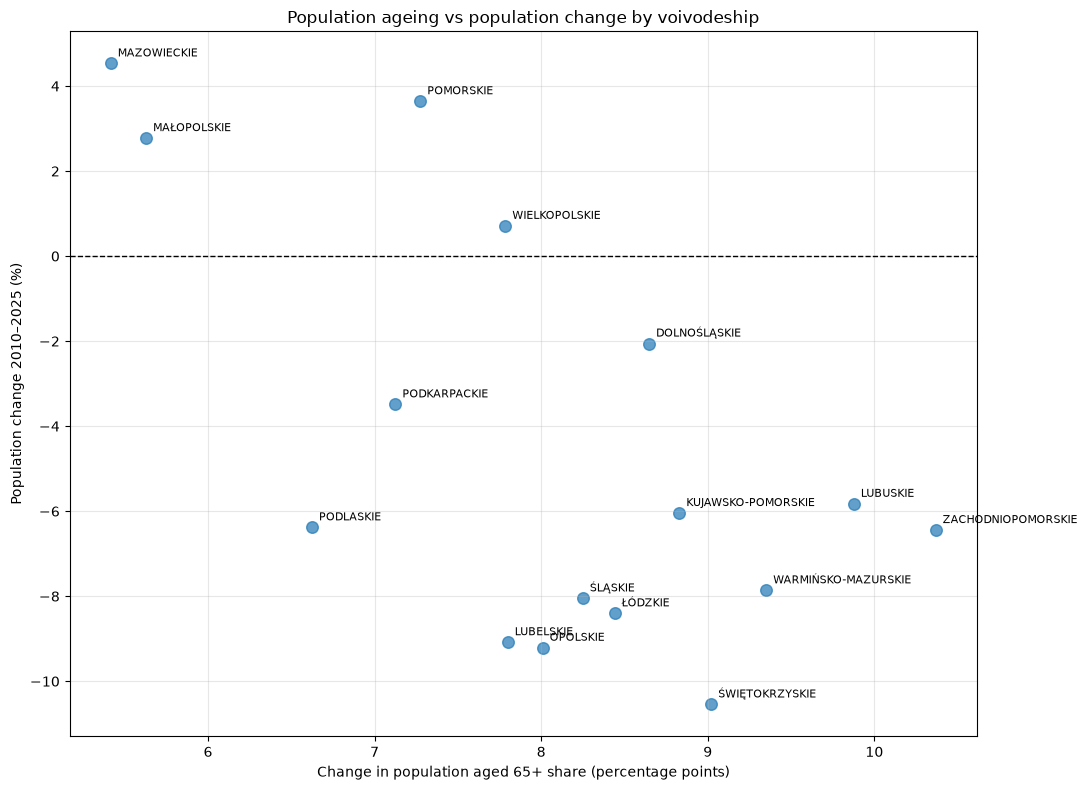

In [39]:
plt.figure(figsize=(11, 8))

plt.scatter(
    h3_data["ageing_change_pp"],
    h3_data["population_change_pct"],
    s=70,
    alpha=0.7
)

for _, row in h3_data.iterrows():
    plt.annotate(
        row["voivodeship"],
        (
            row["ageing_change_pp"],
            row["population_change_pct"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Change in population aged 65+ share (percentage points)")
plt.ylabel("Population change 2010–2025 (%)")
plt.title("Population ageing vs population change by voivodeship")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

The analysis indicates a negative association between population ageing and
long-term population change across Polish voivodeships.

The Pearson correlation between the increase in the share of population aged
65+ and population change between 2010 and 2025 was -0.634 (p = 0.0084),
indicating a moderately strong negative linear relationship.

The Spearman correlation was -0.500 (p = 0.0486), indicating a moderate
negative monotonic relationship.

These results are consistent with Hypothesis 3: voivodeships experiencing
stronger increases in the share of older residents tended to experience less
favourable population change.

However, the analysis is based on only 16 voivodeships and should therefore
be interpreted cautiously. In addition, the relationship does not establish
causality. Population ageing may both contribute to and result from broader
demographic processes, including natural decrease and the migration of
younger population groups.

## 4. Summary of hypothesis testing

The table below summarizes the main statistical results for the three
hypotheses examined in the analysis.

In [40]:
results_summary = pd.DataFrame({
    "hypothesis": [
        "H1: Unemployment vs migration",
        "H2: Salary vs migration",
        "H3: Ageing vs population change"
    ],

    "analysis_level": [
        "Regional averages",
        "Regional averages",
        "Long-term regional change"
    ],

    "pearson_r": [
        h1_regional_pearson_r,
        h2_regional_pearson_r,
        h3_pearson_r
    ],

    "pearson_p": [
        h1_regional_pearson_p,
        h2_regional_pearson_p,
        h3_pearson_p
    ],

    "spearman_rho": [
        h1_regional_spearman_rho,
        h2_regional_spearman_rho,
        h3_spearman_rho
    ],

    "spearman_p": [
        h1_regional_spearman_p,
        h2_regional_spearman_p,
        h3_spearman_p
    ]
})

display(
    results_summary.round(4)
)

,hypothesis,analysis_level,pearson_r,pearson_p,spearman_rho,spearman_p
0,H1: Unemployment vs migration,Regional averages,-0.6708,0.0045,-0.6676,0.0047
1,H2: Salary vs migration,Regional averages,0.8289,0.0001,0.7147,0.0019
2,H3: Ageing vs population change,Long-term regional change,-0.6340,0.0084,-0.5000,0.0486


### Main findings

The statistical analysis produced results consistent with all three initial
research hypotheses.

**H1 — Unemployment and migration:**  
Voivodeships with higher average registered unemployment tended to have less
favourable migration balances. The regional Pearson correlation was -0.671
and the Spearman correlation was -0.668.

**H2 — Salary and migration:**  
Voivodeships with higher average monthly gross salary per employee tended to
have more favourable migration balances. This was the strongest relationship
identified in the regional analysis, with a Pearson correlation of 0.829 and
a Spearman correlation of 0.715.

**H3 — Population ageing and population change:**  
Voivodeships with stronger increases in the share of population aged 65+
tended to experience less favourable population change. The Pearson
correlation was -0.634 and the Spearman correlation was -0.500.

Overall, the results suggest that regional demographic trends are associated
with both socioeconomic conditions and population age structure. However,
the observed correlations do not establish causal relationships, and the
relatively small number of voivodeships should be considered when
interpreting the regional results.

## 5. Limitations

Several limitations should be considered when interpreting the results:

- The regional analyses are based on only 16 Polish voivodeships.
- Correlation does not imply causation, and other factors may influence both
  demographic and socioeconomic indicators.
- The dataset has a panel structure, meaning that repeated yearly observations
  for the same voivodeships are not fully independent.
- Migration data for 2015 were excluded due to data quality limitations.
- Salary values are nominal and have not been adjusted for inflation.
- Population estimates around 2020 should be interpreted cautiously because
  population balances were rebased using the results of the 2021 Census.
- The salary indicator represents monthly gross salary per employee within
  the scope of the selected GUS statistical series and should not be
  interpreted as the average income of all residents.